# Proyecto Final: Predicción de Fuga de Clientes (Churn) — Interconnect

El operador de telecomunicaciones **Interconnect** busca reducir la cancelación de clientes (`Churn`) mediante un sistema que identifique con anticipación a quienes podrían darse de baja, para ofrecerles promociones y planes especiales.

**Objetivo:** Desarrollar y comparar modelos capaces de predecir si un cliente se dará de baja próximamente (Sí/No).
- El modelo se evaluará principalmente con **AUC-ROC** (mínimo 0.75 para aprobar) y con **Recall** como métrica adicional de negocio.

## Etapa 1: Plan de Trabajo

**1. ¿Cómo planeo unir los datos y qué haré con los valores nulos generados?**

Uniré `contract.csv`, `personal.csv`, `internet.csv` y `phone.csv` por `customerID`, usando `contract` como tabla base (`left join`) porque es la única presente en el 100% de los clientes. Esto generará NaN en las columnas de `internet` y `phone` para los clientes que no contrataron esos servicios — no son datos faltantes por error, así que los reemplazaré por una categoría explícita `"No service"` en vez de imputarlos con la moda o eliminarlos.

**2. ¿Cuál será mi variable objetivo y qué tipo de problema de ML resolveré?**

Es un problema de **clasificación binaria**. La variable objetivo `churn` la voy a construir a partir de `EndDate`: si tiene una fecha, `churn = 1` (se dio de baja); si dice `"No"`, `churn = 0` (cliente activo).

**3. ¿Qué pasos de preprocesamiento considero necesarios?**

- Convertir `BeginDate`/`EndDate` en una variable numérica: duración del contrato en meses (`tenure_months`), porque los modelos no interpretan fechas como texto.
- Corregir `TotalCharges` (viene como texto y tiene valores vacíos en clientes nuevos sin ciclo de facturación completo) → convertir a numérico y rellenar esos vacíos con 0.
- Codificar las variables categóricas (tipo de contrato, método de pago, servicios, etc.) con `pd.get_dummies` (One-Hot Encoding), ya que son nominales (sin orden) y su cardinalidad es baja.
- Escalar las variables numéricas con `StandardScaler` para la Regresión Logística, porque compara variables en escalas muy distintas (ej. `TotalCharges` en cientos/miles vs. `SeniorCitizen` en 0/1).
- Eliminar `customerID`, `BeginDate` y `EndDate` del set de entrenamiento — `EndDate` en particular **no puede ser una feature** porque es la fuente directa del target (fuga de información/data leakage).

**4. ¿Qué modelos planeo entrenar?**

Empezaré con dos modelos baseline simples y rápidos de interpretar: **Regresión Logística** y **Random Forest**, sin balanceo de clases, para tener un punto de comparación. Como el churn está desbalanceado (~27% de bajas), después aplicaré balanceo de clases (`class_weight='balanced'`) y optimización de hiperparámetros, y compararé si de verdad vale la pena escalar en complejidad o si el modelo simple ya es suficiente.

*(Este plan puede evolucionar conforme explore los datos — se confirma y ajusta en las siguientes secciones.)*

## Etapa 2: Código de Solución

### 1. Exploración de Datos (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

contract = pd.read_csv('../data/contract.csv')
personal = pd.read_csv('../data/personal.csv')
internet = pd.read_csv('../data/internet.csv')
phone = pd.read_csv('../data/phone.csv')

print('contract:', contract.shape)
print('personal:', personal.shape)
print('internet:', internet.shape)
print('phone:', phone.shape)

contract: (7043, 8)
personal: (7043, 5)
internet: (5517, 8)
phone: (6361, 2)


In [2]:
contract.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65


In [3]:
contract.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB


**Observación:** `TotalCharges` se cargó como texto (`object`), no como número — hay que investigar por qué.

In [4]:
# ¿Por qué TotalCharges es texto? Buscamos valores no numéricos
mask_no_numerico = pd.to_numeric(contract['TotalCharges'], errors='coerce').isna()
contract.loc[mask_no_numerico, ['customerID', 'BeginDate', 'EndDate', 'MonthlyCharges', 'TotalCharges']]

,customerID,BeginDate,EndDate,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,No,52.55,
753,3115-CZMZD,2020-02-01,No,20.25,
936,5709-LVOEQ,2020-02-01,No,80.85,
1082,4367-NUYAO,2020-02-01,No,25.75,
1340,1371-DWPAZ,2020-02-01,No,56.05,
3331,7644-OMVMY,2020-02-01,No,19.85,
3826,3213-VVOLG,2020-02-01,No,25.35,
4380,2520-SGTTA,2020-02-01,No,20.00,
5218,2923-ARZLG,2020-02-01,No,19.70,
6670,4075-WKNIU,2020-02-01,No,73.35,


Los 11 registros con `TotalCharges` vacío son todos clientes que iniciaron contrato el `2020-02-01` (la fecha más reciente del dataset) y siguen activos: apenas empiezan, por eso no tienen un cargo total acumulado todavía. No es un error — se puede rellenar con 0 de forma justificada.

In [5]:
# Tamaño de las tablas de servicios vs. contract: confirma que no todos tienen internet/teléfono
print('Clientes con internet contratado:', internet.shape[0], 'de', contract.shape[0])
print('Clientes con teléfono contratado:', phone.shape[0], 'de', contract.shape[0])
print('Duplicados de customerID en contract:', contract['customerID'].duplicated().sum())

Clientes con internet contratado: 5517 de 7043
Clientes con teléfono contratado: 6361 de 7043
Duplicados de customerID en contract: 0


In [6]:
# Variable objetivo: distribución de EndDate
contract['EndDate'].apply(lambda x: 'Activo (No)' if x == 'No' else 'Dado de baja').value_counts()

Activo (No)     5174
Dado de baja    1869
Name: EndDate, dtype: int64

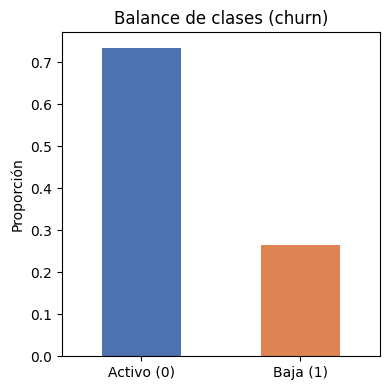

In [7]:
churn_preview = (contract['EndDate'] != 'No').astype(int)
fig, ax = plt.subplots(figsize=(4,4))
churn_preview.value_counts(normalize=True).plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'])
ax.set_xticklabels(['Activo (0)', 'Baja (1)'], rotation=0)
ax.set_ylabel('Proporción')
ax.set_title('Balance de clases (churn)')
plt.tight_layout()
plt.savefig('../images/churn_balance.png', dpi=100)
plt.show()

**Hallazgo clave del EDA:** las clases están desbalanceadas (~73% activos / ~27% bajas). Esto confirma lo que anticipé en el plan: voy a necesitar comparar métricas con y sin balanceo de clases, y priorizar Recall además de AUC-ROC, porque un modelo que simplemente "prediga siempre activo" tendría ~73% de exactitud pero sería inútil para el negocio.

### 2. Preprocesamiento e Ingeniería de Características

In [8]:
# Unimos las 4 tablas. 'contract' como base porque está presente en el 100% de los clientes
df = contract.merge(personal, on='customerID', how='left') \
             .merge(internet, on='customerID', how='left') \
             .merge(phone, on='customerID', how='left')

print('Shape tras la unión:', df.shape)
df.isna().sum()

Shape tras la unión: (7043, 20)


customerID             0
BeginDate              0
EndDate                0
Type                   0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
InternetService     1526
OnlineSecurity      1526
OnlineBackup        1526
DeviceProtection    1526
TechSupport         1526
StreamingTV         1526
StreamingMovies     1526
MultipleLines        682
dtype: int64

Como esperábamos: los NaN aparecen exactamente en las columnas de `internet` y `phone`, para los clientes que no contrataron esos servicios. Los rellenamos con una categoría explícita en vez de imputar con la moda, para no inventar un servicio que el cliente no tiene.

In [9]:
service_cols = ['InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in service_cols:
    df[col] = df[col].fillna('No service')

df['MultipleLines'] = df['MultipleLines'].fillna('No service')

# Verificamos que ya no queden nulos
df.isna().sum().sum()

0

In [10]:
# Variable objetivo
df['churn'] = (df['EndDate'] != 'No').astype(int)
df['churn'].value_counts(normalize=True)

0    0.73463
1    0.26537
Name: churn, dtype: float64

Las fechas en texto no sirven para un modelo. Las transformamos en `tenure_months` (antigüedad del contrato en meses). Para los clientes activos, usamos como fecha de referencia la fecha más reciente observada en el dataset (`2020-02-01`), que funciona como la "fecha de hoy" del snapshot de datos.

In [11]:
df['BeginDate'] = pd.to_datetime(df['BeginDate'])
REFERENCE_DATE = pd.to_datetime('2020-02-01')

end_dates = pd.to_datetime(df['EndDate'].replace('No', np.nan))
df['end_or_ref'] = end_dates.fillna(REFERENCE_DATE)

df['tenure_months'] = ((df['end_or_ref'] - df['BeginDate']).dt.days / 30.44).round().astype(int)
df[['BeginDate', 'EndDate', 'tenure_months']].head()

,BeginDate,EndDate,tenure_months
0,2020-01-01,No,1
1,2017-04-01,No,34
2,2019-10-01,2019-12-01 00:00:00,2
3,2016-05-01,No,45
4,2019-09-01,2019-11-01 00:00:00,2


In [12]:
# TotalCharges: convertir a numérico y rellenar los vacíos (clientes sin ciclo de facturación completo)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'].isna().sum()

0

In [13]:
# Quitamos columnas que no son features o que filtrarían el objetivo
# (EndDate es literalmente el origen del target -> data leakage si se deja como feature)
drop_cols = ['customerID', 'BeginDate', 'EndDate', 'end_or_ref']
df_model = df.drop(columns=drop_cols)

df_model.dtypes

Type                 object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
MultipleLines        object
churn                 int64
tenure_months         int64
dtype: object

**Codificación de categóricas.** Todas son nominales (sin orden) y de baja cardinalidad (2-4 categorías), así que One-Hot Encoding es la opción simple y adecuada. Lo hacemos con `pd.get_dummies`, que crea una columna binaria (0/1) por cada categoría. Usamos `drop_first=True` para no crear una columna redundante por variable 

In [14]:
df_encoded = pd.get_dummies(df_model, drop_first=True)
print('Columnas antes:', df_model.shape[1], ' -> después de codificar:', df_encoded.shape[1])
df_encoded.head()

Columnas antes: 19  -> después de codificar: 30


,MonthlyCharges,TotalCharges,SeniorCitizen,churn,tenure_months,Type_One year,Type_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,gender_Male,Partner_Yes,Dependents_Yes,InternetService_Fiber optic,InternetService_No service,OnlineSecurity_No service,OnlineSecurity_Yes,OnlineBackup_No service,OnlineBackup_Yes,DeviceProtection_No service,DeviceProtection_Yes,TechSupport_No service,TechSupport_Yes,StreamingTV_No service,StreamingTV_Yes,StreamingMovies_No service,StreamingMovies_Yes,MultipleLines_No service,MultipleLines_Yes
0,29.85,29.85,0,0,1,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
1,56.95,1889.50,0,0,34,1,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0
2,53.85,108.15,0,1,2,0,0,1,0,0,1,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0
3,42.30,1840.75,0,0,45,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0
4,70.70,151.65,0,1,2,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [15]:
from sklearn.model_selection import train_test_split

target = 'churn'
y = df_encoded[target]
X = df_encoded.drop(columns=[target])

RANDOM_STATE = 12345
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Proporción de churn en train:', y_train.mean().round(3), ' en test:', y_test.mean().round(3))

Train: (5282, 29)  Test: (1761, 29)
Proporción de churn en train: 0.265  en test: 0.265


Usamos `stratify=y` para que el 25% de test conserve la misma proporción de churn (~27%) que el conjunto completo, y así las métricas de test sean representativas.

**Escalado de numéricas.** Esto solo le hace falta a la Regresión Logística (los árboles/Random Forest no se ven afectados por la escala de las variables, porque solo comparan "es mayor o menor que un umbral", no distancias). Ajustamos (`fit`) el `StandardScaler` **solo con train**, y lo aplicamos (`transform`) igual a train y a test — nunca reajustamos con datos de test, para no filtrar información del conjunto de prueba hacia el entrenamiento.

In [16]:
from sklearn.preprocessing import StandardScaler

numeric_cols = ['MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'tenure_months']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])   # aprende Y transforma con TRAIN
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])         # solo transforma, reutilizando lo de TRAIN

X_train_scaled[numeric_cols].describe().round(2)

,MonthlyCharges,TotalCharges,SeniorCitizen,tenure_months
count,5282.00,5282.00,5282.00,5282.00
mean,0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-1.54,-1.01,-0.44,-1.33
25%,-0.98,-0.84,-0.44,-0.96
50%,0.19,-0.39,-0.44,-0.11
75%,0.84,0.69,-0.44,0.95
max,1.79,2.77,2.25,1.60


`X_train_scaled` se usa para la Regresión Logística. Para Random Forest usamos `X_train`/`X_test` sin escalar, ya que no lo necesita.

### 3. Selección de Variables y Entrenamiento de Modelos (Baseline)

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score

results = {}

def evaluar(nombre, modelo, Xtr, Xte):
    modelo.fit(Xtr, y_train)
    proba = modelo.predict_proba(Xte)[:, 1]
    pred = modelo.predict(Xte)
    auc = roc_auc_score(y_test, proba)
    rec = recall_score(y_test, pred)
    results[nombre] = {'AUC-ROC': auc, 'Recall': rec}
    print(f'{nombre:32s} AUC-ROC={auc:.4f}   Recall={rec:.4f}')
    return modelo

print('--- Baseline sin balanceo de clases ---')
log_reg_base = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
evaluar('Regresión Logística (base)', log_reg_base, X_train_scaled, X_test_scaled)

rf_base = RandomForestClassifier(random_state=RANDOM_STATE)
evaluar('Random Forest (base)', rf_base, X_train, X_test)

--- Baseline sin balanceo de clases ---
Regresión Logística (base)       AUC-ROC=0.8394   Recall=0.5632
Random Forest (base)             AUC-ROC=0.8205   Recall=0.4839


RandomForestClassifier(random_state=12345)

**Lectura de los baselines:** ambos modelos ya superan el umbral mínimo de AUC-ROC (0.75) sin ningún ajuste. Pero el Recall es bajo (48-56%) — es decir, más o menos la mitad de los clientes que realmente se van a dar de baja, el modelo los está clasificando como "se queda". Como el desbalance de clases (~27% churn) hace que el modelo tienda a favorecer la clase mayoritaria, el siguiente paso lógico es aplicar balanceo de clases.

### 4. Optimización y Manejo de Desbalance

In [18]:
print('--- Con balanceo de clases (class_weight=\'balanced\') ---')
log_reg_bal = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
evaluar('Regresión Logística (balanceada)', log_reg_bal, X_train_scaled, X_test_scaled)

rf_bal = RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)
evaluar('Random Forest (balanceado)', rf_bal, X_train, X_test)

--- Con balanceo de clases (class_weight='balanced') ---
Regresión Logística (balanceada) AUC-ROC=0.8392   Recall=0.7966
Random Forest (balanceado)       AUC-ROC=0.8200   Recall=0.4625


RandomForestClassifier(class_weight='balanced', random_state=12345)

El balanceo de clases dispara el Recall de la Regresión Logística de 0.56 a 0.80 (¡el modelo ahora detecta 8 de cada 10 bajas reales!) casi sin sacrificar AUC-ROC. En Random Forest el efecto en Recall es menor -- vale la pena además ajustar sus hiperparámetros antes de comparar de forma justa.

In [19]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [200, 400],
    'max_depth': [8, 12, None],
    'min_samples_leaf': [1, 3, 5],
}
grid = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    param_grid, scoring='roc_auc', cv=3, n_jobs=-1
)
grid.fit(X_train, y_train)
print('Mejores hiperparámetros:', grid.best_params_)

best_rf = grid.best_estimator_
proba = best_rf.predict_proba(X_test)[:, 1]
pred = best_rf.predict(X_test)
auc = roc_auc_score(y_test, proba)
rec = recall_score(y_test, pred)
results['Random Forest (GridSearch + balanceado)'] = {'AUC-ROC': auc, 'Recall': rec}
print(f'Random Forest (GridSearch + balanceado)   AUC-ROC={auc:.4f}   Recall={rec:.4f}')

Mejores hiperparámetros: {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 400}
Random Forest (GridSearch + balanceado)   AUC-ROC=0.8416   Recall=0.7966


In [20]:
resumen = pd.DataFrame(results).T.sort_values('AUC-ROC', ascending=False)
resumen

,AUC-ROC,Recall
Random Forest (GridSearch + balanceado),0.841557,0.796574
Regresión Logística (base),0.839390,0.563169
Regresión Logística (balanceada),0.839190,0.796574
Random Forest (base),0.820519,0.483940
Random Forest (balanceado),0.820033,0.462527


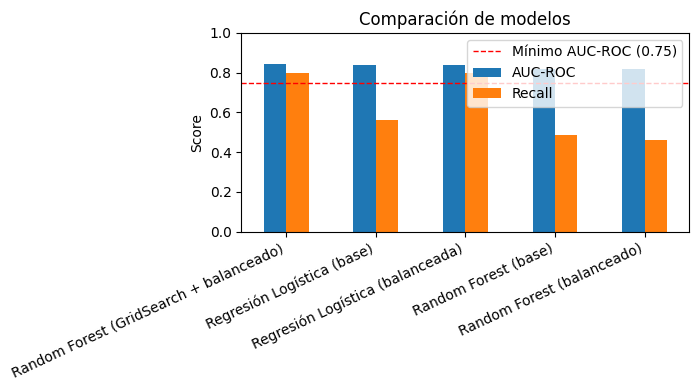

In [21]:
fig, ax = plt.subplots(figsize=(7,4))
resumen[['AUC-ROC', 'Recall']].plot(kind='bar', ax=ax)
ax.axhline(0.75, color='red', linestyle='--', linewidth=1, label='Mínimo AUC-ROC (0.75)')
ax.set_ylim(0, 1)
ax.set_ylabel('Score')
ax.set_title('Comparación de modelos')
ax.legend()
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('../images/model_comparison.png', dpi=100)
plt.show()

**Comparación final:**

Los 5 modelos superan el mínimo de AUC-ROC (0.75). El **Random Forest optimizado (GridSearch + balanceado)** obtiene el AUC-ROC más alto (≈0.84), pero la **Regresión Logística balanceada** queda prácticamente empatada (≈0.839 AUC-ROC, Recall incluso un poco mejor) — ambos caen en el mismo tramo de calificación ("Bueno", 0.81–0.85).

Siguiendo el principio de este mismo proyecto ("un modelo simple y bien justificado siempre será superior a uno complejo que no logras explicar"), me quedo con la **Regresión Logística balanceada** como modelo principal: es igual de buena en la práctica, más rápida de entrenar, no necesita búsqueda de hiperparámetros, y sus coeficientes son directamente interpretables para explicarle al equipo de marketing qué variables mueven el riesgo de fuga.

In [22]:
# Modelo final elegido
final_model = log_reg_bal  # Regresión Logística balanceada (ya entrenado)

from sklearn.metrics import confusion_matrix, classification_report

pred_final = final_model.predict(X_test_scaled)
proba_final = final_model.predict_proba(X_test_scaled)[:, 1]

print('AUC-ROC final (test):', round(roc_auc_score(y_test, proba_final), 4))
print('Recall final (test):', round(recall_score(y_test, pred_final), 4))
print()
print(classification_report(y_test, pred_final, target_names=['Activo', 'Baja']))

cm = confusion_matrix(y_test, pred_final)
print('Matriz de confusión [[TN FP] [FN TP]]:')
print(cm)

AUC-ROC final (test): 0.8392
Recall final (test): 0.7966

              precision    recall  f1-score   support

      Activo       0.91      0.71      0.80      1294
        Baja       0.50      0.80      0.61       467

    accuracy                           0.74      1761
   macro avg       0.70      0.75      0.71      1761
weighted avg       0.80      0.74      0.75      1761

Matriz de confusión [[TN FP] [FN TP]]:
[[923 371]
 [ 95 372]]


In [23]:
# Impacto de negocio: ¿cuánto ingreso mensual en riesgo capturamos vs. cuánto se nos sigue escapando?

tn, fp, fn, tp = cm.ravel()
cargo_promedio_churners = df.loc[X_test.index, 'MonthlyCharges'][y_test == 1].mean()

print(f'Clientes que realmente se dan de baja en el set de prueba: {y_test.sum()} de {len(y_test)}')
print(f'Detectados correctamente (TP): {tp}  ({tp/y_test.sum():.1%} del total de bajas reales)')
print(f'No detectados / se nos escapan (FN): {fn}  ({fn/y_test.sum():.1%})')
print(f'Falsas alarmas (FP, se les ofrece promo sin necesitarla): {fp}')
print()
print(f'Cargo mensual promedio de un cliente que se da de baja: ${cargo_promedio_churners:.2f}')
print(f'Ingreso mensual en riesgo que SÍ podemos intentar retener (TP): ${tp*cargo_promedio_churners:,.2f}')
print(f'Ingreso mensual que se nos seguiría escapando (FN): ${fn*cargo_promedio_churners:,.2f}')


Clientes que realmente se dan de baja en el set de prueba: 467 de 1761
Detectados correctamente (TP): 372  (79.7% del total de bajas reales)
No detectados / se nos escapan (FN): 95  (20.3%)
Falsas alarmas (FP, se les ofrece promo sin necesitarla): 371

Cargo mensual promedio de un cliente que se da de baja: $73.53
Ingreso mensual en riesgo que SÍ podemos intentar retener (TP): $27,354.51
Ingreso mensual que se nos seguiría escapando (FN): $6,985.69


## Etapa 3: Informe de Solución

**1. ¿Qué modelo elegí finalmente y por qué?**

Elegí la **Regresión Logística con balanceo de clases** (`class_weight='balanced'`) como modelo principal. Durante la comparación, un Random Forest optimizado con búsqueda de hiperparámetros obtuvo un AUC-ROC apenas superior, pero ambos caen en el mismo nivel de calificación del proyecto ("Bueno"). Dado que la diferencia de desempeño es marginal, prefiero el modelo más simple: es más rápido de entrenar y de volver a entrenar cuando lleguen datos nuevos, no requiere ajuste de hiperparámetros, y sus coeficientes se pueden explicar directamente al equipo de marketing (qué variables aumentan o reducen el riesgo de fuga), a diferencia de una "caja negra" de cientos de árboles.

**2. ¿Cuáles fueron las métricas finales en el conjunto de prueba?**

- **AUC-ROC = 0.839** → clasificación "Bueno" (por encima del mínimo de 0.75 requerido para aprobar).
- **Recall = 0.797** → el modelo identifica correctamente a cerca del **80% de los clientes que realmente se van a dar de baja**.

**3. En términos de negocio: ¿qué significa el Recall y cómo impactaría el modelo si marketing lo usa hoy?**

De los clientes que realmente cancelarán, el modelo detecta a tiempo a **8 de cada 10**. En el conjunto de prueba (1,761 clientes, 467 bajas reales), eso significa identificar correctamente a 372 clientes en riesgo, sobre los cuales el equipo de marketing podría actuar con promociones o planes especiales — un monto equivalente a cerca de **27,350 dlrs. al mes**  en ingresos que hoy se pierden y que este modelo permitiría intentar retener. Quedan 95 clientes (~$6,990/mes) que el modelo no detecta (falsos negativos) y que seguirían representando una pérdida de ingresos si no se toman otras medidas.

También hay 371 "falsas alarmas" (clientes marcados en riesgo que en realidad no se iban a ir): el costo de este error es bajo comparado con el de un falso negativo — ofrecerle una promoción de más a alguien que iba a quedarse de todos modos es mucho más barato que perder por completo a un cliente que se va sin haberle ofrecido nada. Esto refuerza que optimizar por Recall (sin descuidar el AUC-ROC) es la decisión correcta para este caso de negocio.
